**Setup python**

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(['science'])

**Load PCB data**

In [4]:
# Load the data from MNIST-5-6-Subset.txt
data_file_path = r"data\PCB.dt"
data_raw = np.loadtxt(data_file_path)

print(type(data_raw))
print(data_raw.shape)

<class 'numpy.ndarray'>
(28, 2)


**Visualise data**

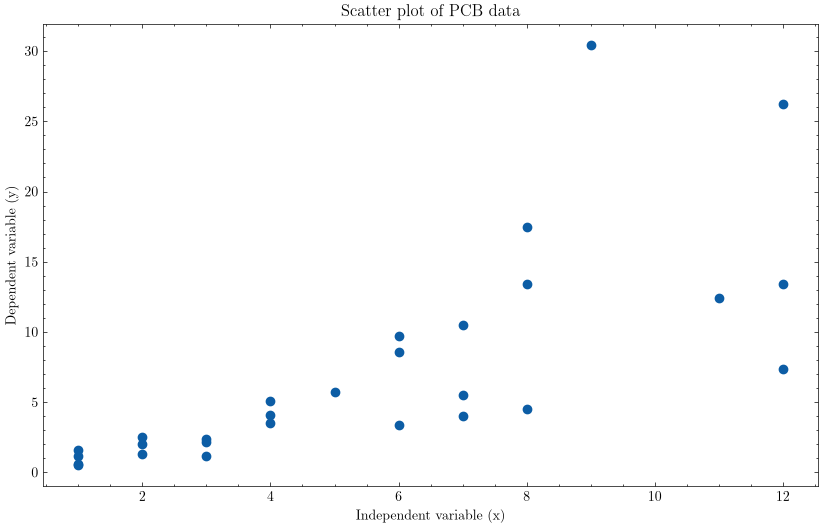

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(data_raw[:, 0], data_raw[:, 1])
plt.xlabel("Independent variable (x)")
plt.ylabel("Dependent variable (y)")
plt.title("Scatter plot of PCB data")
plt.show()

**Task 1: Create linear regression function**

In [6]:
# Create linear regression function
def LR(y, X):

    # Include a bias term (intercept) in the independent variables
    X = np.column_stack([np.ones(X.shape[0]), X])

    # Calculate the parameter estimates
    w = np.linalg.inv(X.T @ X) @ X.T @ y

    # Calculate predicted values
    y_pred = X @ w
 
    # Calculate the residuals
    residuals = y - y_pred

    # Calculate the mean squared error (MSE)
    mse = np.mean(residuals ** 2)

    return w, mse, y_pred


**Task 2: Build non-linear model**

In [7]:
# Prepare the data for linear regression
y = data_raw[:, 1]  # Dependent variable
x = data_raw[:, 0]  # Independent variable

# Transformation of the dependent variable 
y_log = np.log(y)

# Calculate the parameter estimates using linear regression
w, mse_lin, y_pred = LR(y_log, x)

# Calculate the predicted values of the non-transformed dependent variable
mse_non_lin = np.mean((y - np.exp(y_pred)) ** 2)

# Print the results
print("Parameter estimates (w):", w)
print("Mean Squared Error transformed (MSE):", mse_lin)
print("Mean Squared Error non-transformed (MSE):", mse_non_lin)

Parameter estimates (w): [0.03147247 0.25912824]
Mean Squared Error transformed (MSE): 0.29853492489386185
Mean Squared Error non-transformed (MSE): 34.83556116722038


**Task 4. Plot PCB data and model output**

In [8]:
# Create the plot
plt.figure(figsize=(10, 6))

plt.scatter(x, y_log, label="Data points")
plt.plot(x, y_pred, color="red", label="Fitted model")
plt.xlabel("Age of fish (years)")
plt.ylabel("log of PCB residue concentration (ppm)")

plt.title(f"Regression of PCB residue concentration on age of fish")
plt.legend(loc="upper left")
plt.grid(True)

output_dir = "output/"
filename = "PCB_Regression_Plot.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
plt.close()

**Task 5: Calculate R^2**

In [9]:
# Calculate mean of the dependent variable
mean_y = np.mean(y)

# Calculate R^2
R2 = 1 - np.sum((y - np.exp(y_pred))**2) / np.sum((y - mean_y)**2)

# Report R^2
print("R^2:", R2)

R^2: 0.3570135731609858


**Task 6: New non-linear model**

In [10]:
# Calculate x sqrt
x_sqrt = np.sqrt(x)

# Calculate the parameter estimates using linear regression
w, mse, y_pred = LR(y_log, x_sqrt)

# Calculate the mean squared error (MSE) for the non-transformed dependent variable
mse_non_lin = np.mean((y - np.exp(w[0] + w[1] * x_sqrt)) ** 2)

# Report MSE
print("Mean Squared Error transformed (MSE):", mse)
print("Mean Squared Error non-transformed (MSE):", mse_non_lin)

# calculate the predicted values of the non-transformed dependent variable
x_grid = np.linspace(x.min(), x.max(), 200)
y_grid = w[0] + w[1] * np.sqrt(x_grid)

# Plot the data and the fitted model
plt.figure(figsize=(10, 6))

plt.scatter(x, y_log, label="Data points")
plt.plot(x_grid, y_grid, color="red", label="Fitted model")
plt.xlabel("Age of fish (years)")
plt.ylabel("log of PCB residue concentration (ppm)")

plt.title(f"Regression of PCB residue concentration on age of fish")
plt.legend(loc="upper left")
plt.grid(True)

output_dir = "output/"
filename = "PCB_Regression_Plot_2.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
plt.close()

# Calculate R^2 for the transformed model
R2 = 1 - np.sum((y - np.exp(w[0] + w[1] * x_sqrt)) ** 2) / np.sum((y - mean_y) ** 2)

# Report R^2
print("R^2 for the transformed model:", R2)


Mean Squared Error transformed (MSE): 0.23772496260048084
Mean Squared Error non-transformed (MSE): 28.08439017494436
R^2 for the transformed model: 0.48162506692924123
